<a href="https://colab.research.google.com/github/JonerciJon/CSST106/blob/main/Lab_Experiment_3_Histogram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload a sample image (low/varying contrast works best), or cancel for a synthetic one:


Saving 10.jpg to 10.jpg
Loaded image: 10.jpg | Shape: (221, 235, 3)


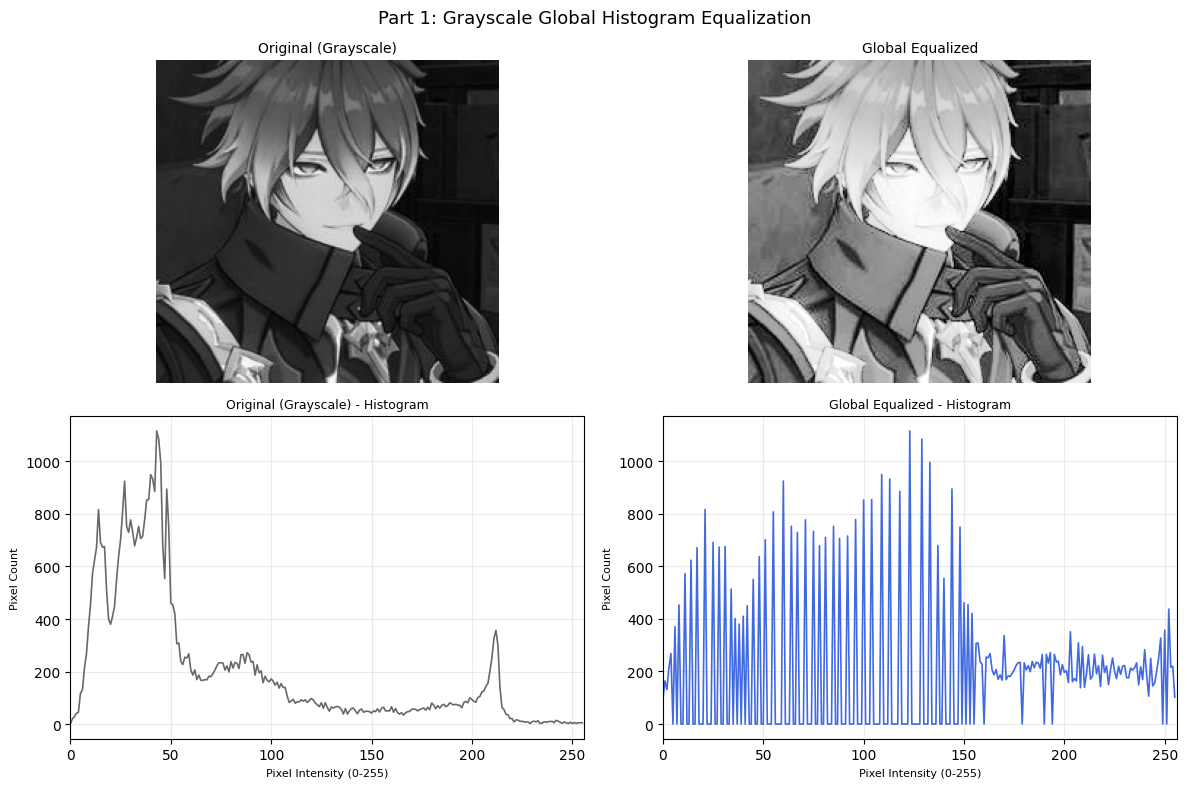

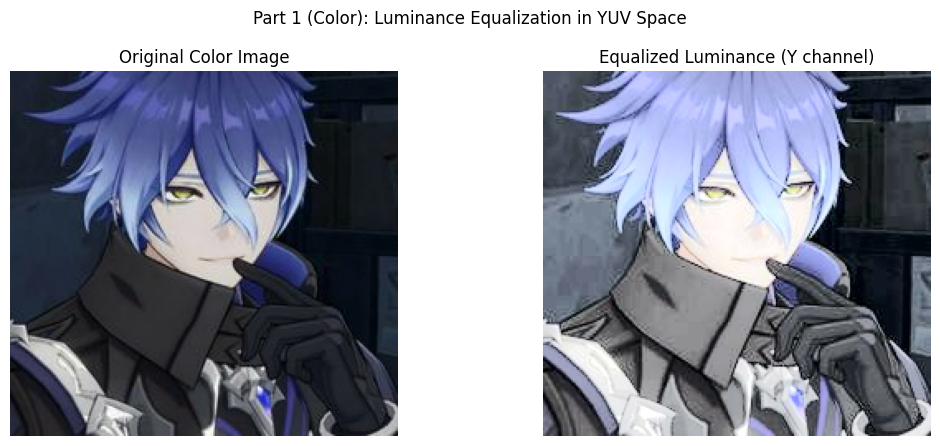

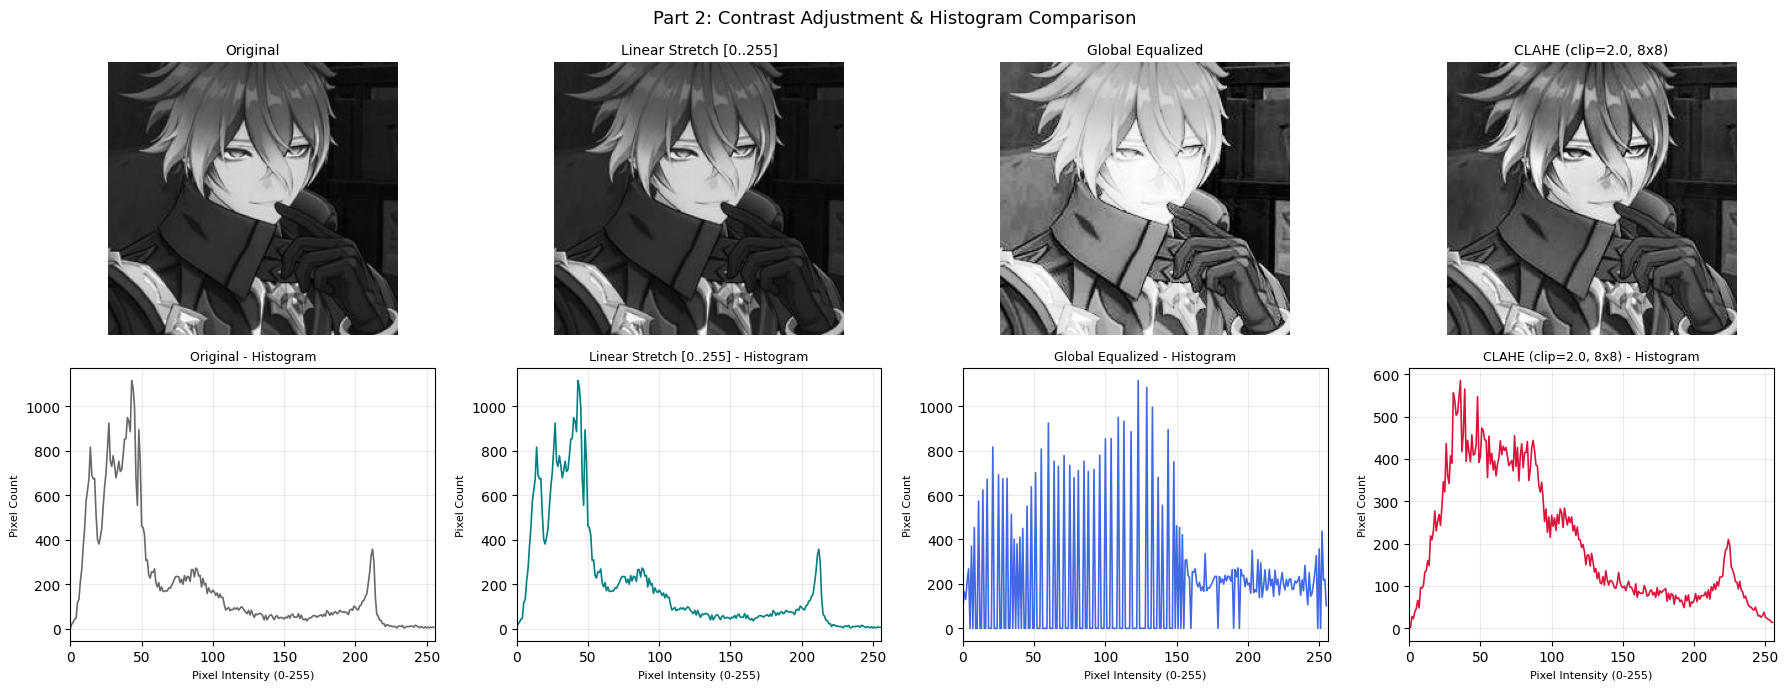

In [1]:
# ==============================================================================
# CSST106 - Histogram Equalization and Contrast Adjustment in Computer Vision
# Colab-compatible OpenCV, NumPy, and Matplotlib script
# ==============================================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


def load_or_create_sample():
    """Upload a low-contrast sample image in Colab or generate a fallback."""
    print("Upload a sample image (low/varying contrast works best), or cancel for a synthetic one:")
    try:
        uploaded = files.upload()
        if uploaded:
            filename = next(iter(uploaded))
            img_bgr = cv2.imread(filename)
            if img_bgr is not None:
                return img_bgr, filename
    except Exception:
        pass

    print("No file uploaded; generating a low-contrast synthetic test image...")
    h, w = 360, 540
    # Create a dark/low-contrast scene with subtle details and slight noise
    base = np.zeros((h, w, 3), dtype=np.uint8)
    base[:, :] = (55, 55, 55)  # Dark gray background

    # Subtle low-contrast objects (intensities clustered between ~45 and ~110)
    cv2.rectangle(base, (40, 50), (220, 300), (75, 85, 70), thickness=-1)
    cv2.circle(base, (370, 175), 90, (95, 80, 75), thickness=-1)
    cv2.line(base, (30, 325), (510, 35), (110, 110, 110), thickness=3)
    cv2.putText(base, "CONTRAST", (295, 185), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (115, 115, 115), 2)

    rng = np.random.default_rng(42)
    noise = rng.normal(0, 6, base.shape).astype(np.int16)
    low_contrast_bgr = np.clip(base.astype(np.int16) + noise, 0, 255).astype(np.uint8)
    cv2.imwrite("low_contrast_sample.jpg", low_contrast_bgr)
    return low_contrast_bgr, "low_contrast_sample.jpg"


def plot_image_and_hist(ax_img, ax_hist, img_gray, title, color="black"):
    """Helper to display a grayscale image and its 256-bin intensity histogram."""
    ax_img.imshow(img_gray, cmap="gray", vmin=0, vmax=255)
    ax_img.set_title(title, fontsize=10)
    ax_img.axis("off")

    hist = cv2.calcHist([img_gray], [0], None, [256], [0, 256]).ravel()
    ax_hist.plot(hist, color=color, linewidth=1.2)
    ax_hist.set_xlim([0, 256])
    ax_hist.set_title(f"{title} - Histogram", fontsize=9)
    ax_hist.set_xlabel("Pixel Intensity (0-255)", fontsize=8)
    ax_hist.set_ylabel("Pixel Count", fontsize=8)
    ax_hist.grid(alpha=0.25)


def run_histogram_lab():
    img_bgr, filename = load_or_create_sample()
    print(f"Loaded image: {filename} | Shape: {img_bgr.shape}")

    # Convert to Grayscale (Part 1, Step 2)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # --------------------------------------------------------------------------
    # PART 1: Global Histogram Equalization (Grayscale & Color via YUV)
    # --------------------------------------------------------------------------
    # Grayscale global equalization
    global_eq = cv2.equalizeHist(gray)

    # Color global equalization: equalize only the Y (luminance) channel in YUV
    # so hue/color balance is preserved instead of distorting RGB channels separately
    img_yuv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YUV)
    img_yuv[:, :, 0] = cv2.equalizeHist(img_yuv[:, :, 0])
    color_eq_bgr = cv2.cvtColor(img_yuv, cv2.COLOR_YUV2BGR)

    # Side-by-side Original vs. Equalized + Histograms
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    fig.suptitle("Part 1: Grayscale Global Histogram Equalization", fontsize=13)
    plot_image_and_hist(axes[0, 0], axes[1, 0], gray, "Original (Grayscale)", color="dimgray")
    plot_image_and_hist(axes[0, 1], axes[1, 1], global_eq, "Global Equalized", color="royalblue")
    plt.tight_layout()
    plt.savefig("part1_global_equalization.png", dpi=150)
    plt.show()

    # Color comparison (Original vs. YUV Luminance Equalized)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    fig.suptitle("Part 1 (Color): Luminance Equalization in YUV Space", fontsize=12)
    axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original Color Image")
    axes[0].axis("off")

    axes[1].imshow(cv2.cvtColor(color_eq_bgr, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Equalized Luminance (Y channel)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.savefig("part1_color_yuv_equalization.png", dpi=150)
    plt.show()

    # --------------------------------------------------------------------------
    # PART 2: Linear Contrast Stretching & CLAHE Comparison
    # --------------------------------------------------------------------------
    # 1. Linear Contrast Adjustment (min-max contrast stretching to [0, 255])
    min_val, max_val = float(gray.min()), float(gray.max())
    if max_val > min_val:
        stretched = np.clip((gray.astype(np.float32) - min_val) * (255.0 / (max_val - min_val)), 0, 255).astype(np.uint8)
    else:
        stretched = gray.copy()

    # 2. Adaptive Histogram Equalization (CLAHE)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    clahe_img = clahe.apply(gray)

    # Compare Original, Linear Stretch, Global Equalization, and CLAHE
    fig, axes = plt.subplots(2, 4, figsize=(18, 7))
    fig.suptitle("Part 2: Contrast Adjustment & Histogram Comparison", fontsize=13)

    variants = [
        (gray, "Original", "dimgray"),
        (stretched, f"Linear Stretch [{int(min_val)}..{int(max_val)}]", "teal"),
        (global_eq, "Global Equalized", "royalblue"),
        (clahe_img, "CLAHE (clip=2.0, 8x8)", "crimson"),
    ]

    for col, (im_data, label, col_line) in enumerate(variants):
        plot_image_and_hist(axes[0, col], axes[1, col], im_data, label, color=col_line)

    plt.tight_layout()
    plt.savefig("part2_contrast_comparison.png", dpi=150)
    plt.show()


if __name__ == "__main__":
    run_histogram_lab()